# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [115]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [ ]:
def get_random_images(filepath, n=1000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [117]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [118]:
def get_imdb_data(imdb_id):
    """Fetch and parse IMDB page data."""
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

    
    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genre_count': len(data.get('genre', [])),
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [119]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [120]:
def create_dataset(image_folder):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    imdb_data = []
    feature_data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            features = extract_color_features(img_path)

            if features is not None:  # Ensure features is not empty
                # Append imdb_id to the features array (assuming features is a 1D array)
                features_with_id = np.append(features, imdb_id)  # Append imdb_id to the features
                feature_data.append(features_with_id)
                imdb_data.append(show_data)
    
    # Define column names for the feature DataFrame
    feature_columns = ['r_mean', 'g_mean', 'b_mean', 'w_mean', 'imdb_id']
    
    imdb_df = pd.DataFrame(imdb_data)
    feature_df = pd.DataFrame(feature_data, columns=feature_columns)
    
    # Save datasets
    imdb_df.to_csv('imdb_data.csv', index=False)
    feature_df.to_csv('feature_data.csv', index=False)
    
    return imdb_df, feature_df

In [121]:
def perform_pca_analysis(feature_df):
    """Perform PCA on features."""
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    return pca, X_pca, n_components

In [122]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  # Limit to n_components
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  # Ensure x-ticks match the number of components
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
    plt.show()

In [123]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [124]:
def plot_pca_features(pca, feature_names, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    # Get the feature loadings
    components = pca.components_
    
    # Create scatter plot
    for i, feature in enumerate(feature_names):
        plt.scatter(components[0, i], components[1, i])
        #plt.annotate(feature, (components[0, i], components[1, i]))
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [125]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [126]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 3D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131, projection='3d')
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    ax1.set_zlabel('PC3')
    
    # Hierarchical
    ax2 = fig.add_subplot(132, projection='3d')
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    ax2.set_zlabel('PC3')
    
    # DBSCAN
    ax3 = fig.add_subplot(133, projection='3d')
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    ax3.set_zlabel('PC3')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [127]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdb_df, feature_df = create_dataset(IMAGE_FOLDER)   

Step 1: Gathering data...


In [128]:
print("\nIMDB Data Sample:")
imdb_df.head()


IMDB Data Sample:


,imdb_id,title,rating,rating_count,content_rating,date_published,genre_count
0,tt0135729,Home Run Derby,8.600000,133,TV-PG,1960-01-09,1
1,tt0050033,The Lucy-Desi Comedy Hour,8.300000,1318,,1957-11-06,2
2,tt0290957,Bärbel Schäfer,1.600000,47,,1995-05-26,1
3,tt0441059,Kaamelott,8.800000,4167,,2005-01-03,3
4,tt0115218,Iron Man,6.500000,3847,TV-Y7,1994-09-24,3


In [129]:
print("\nFeature Data Sample:")
feature_df.head()


Feature Data Sample:


,r_mean,g_mean,b_mean,w_mean,imdb_id
0,136.1742400085034,133.04536033163265,115.896484375,51.93552030187075,tt0135729
1,63.441140518707485,151.38566911139455,124.8919137967687,20.965198058390023,tt0050033
2,117.78970025510205,89.24533641581633,56.35738201530612,42.77026201105442,tt0290957
3,7.450387967687075,7.580184417517007,7.606970131802721,1.6342828798185944,tt0441059
4,153.43262383078232,131.3402954931973,117.01341943027211,42.455990469104314,tt0115218


In [130]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)


print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
evr


Step 4-8: Performing PCA analysis...

Explained variance ratios:


,Explained Variance Ratio
Principal Component,
PC1,0.765533
PC2,0.118096
PC3,0.095617
PC4,0.020754


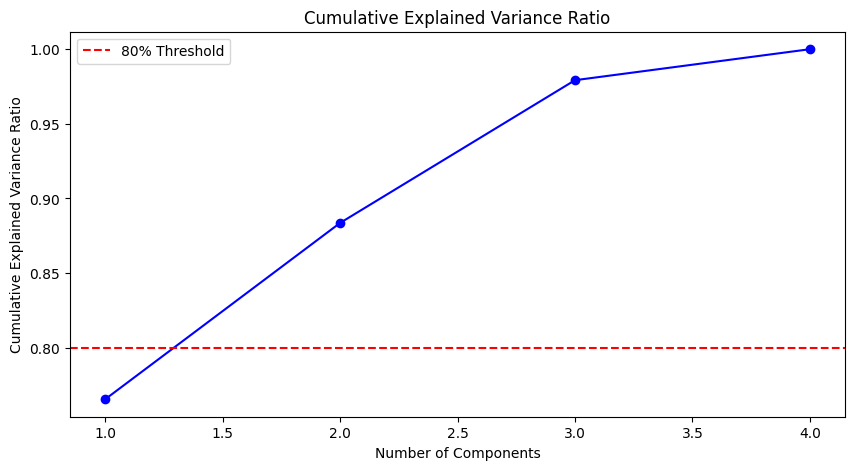

In [131]:
plot_cumulative_variance(pca)

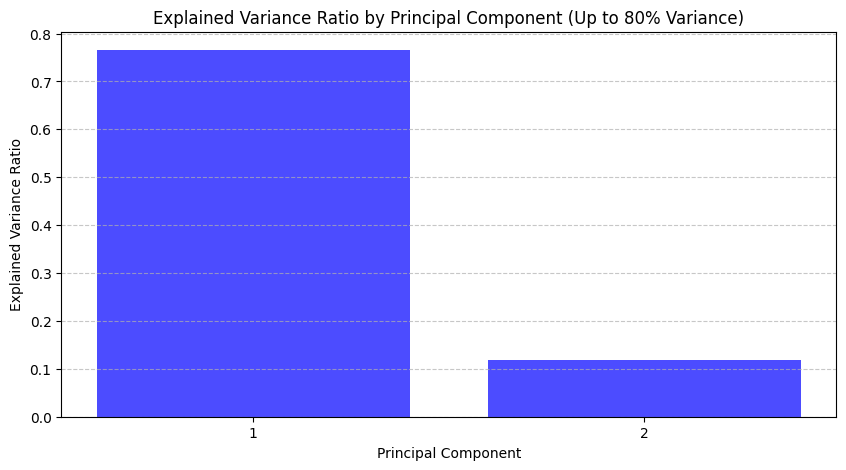

In [132]:
plot_explained_variance(pca, n_components)

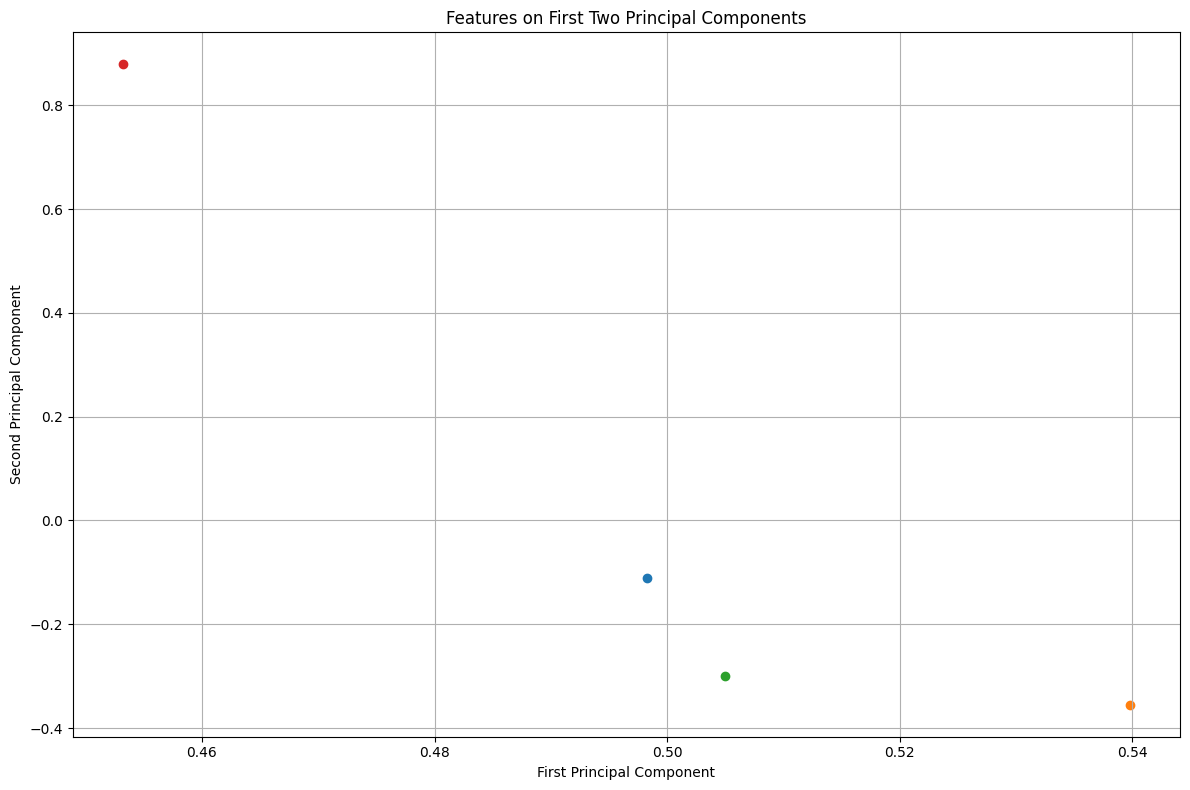

In [133]:
plot_pca_features(pca, feature_names, n_components)

In [134]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
loadings_df


,PC1,PC2
r_mean,0.872818,-0.076649
g_mean,0.945477,-0.244138
b_mean,0.884462,-0.205978
w_mean,0.793887,0.604504


In [135]:
loadings_df.sort_values(by="PC1", ascending=False).head(10)

,PC1,PC2
g_mean,0.945477,-0.244138
b_mean,0.884462,-0.205978
r_mean,0.872818,-0.076649
w_mean,0.793887,0.604504



Step 9-12: Performing clustering analysis...


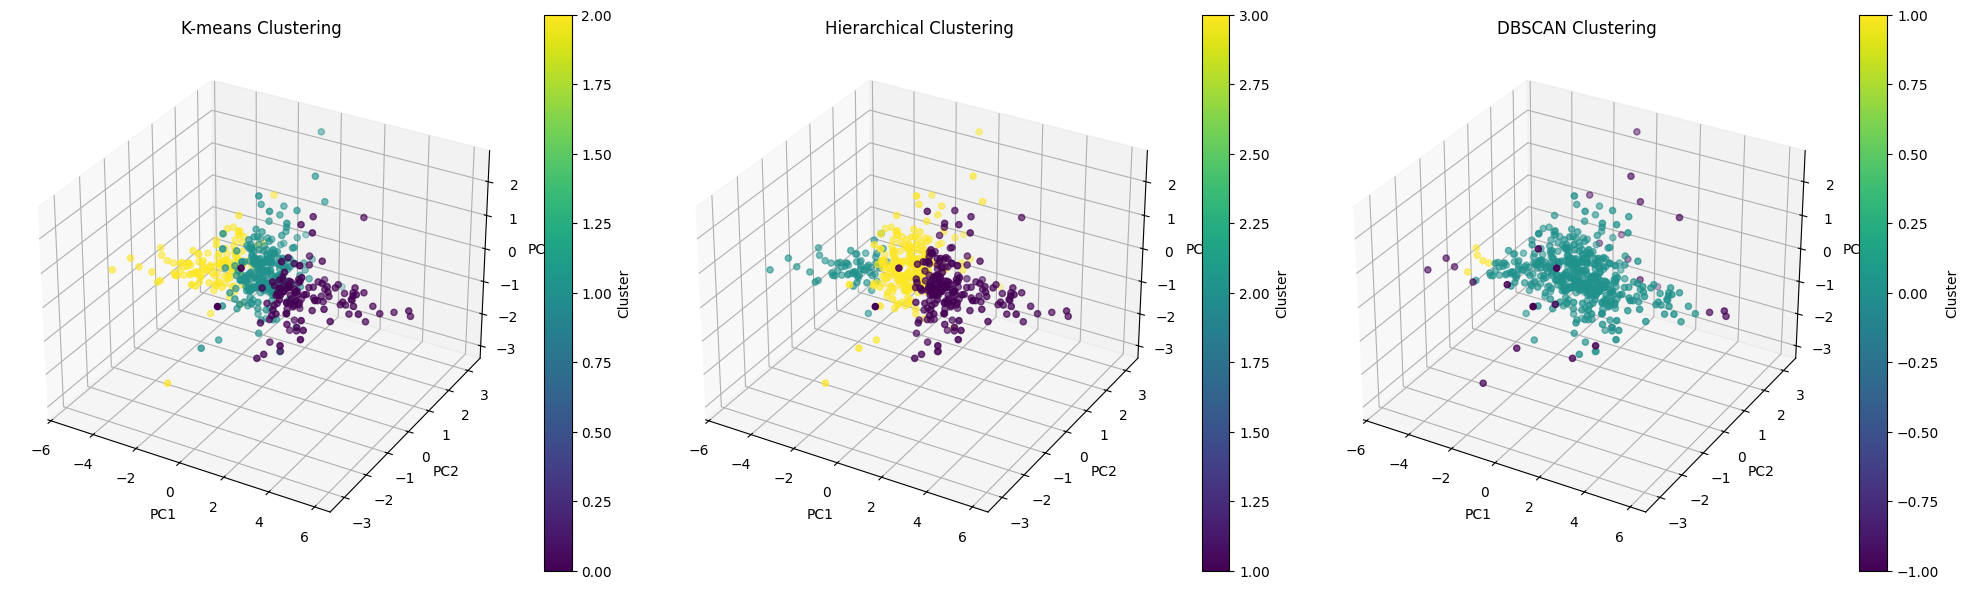

In [136]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)